# SBDMS ML experiments

Run the cells **from top to bottom** (Run -> Run All Cells). Before you start, put `transfusion.data` in the same folder as this notebook.

* **Part A**: donor-return model (real machine learning, UCI Blood Transfusion dataset)
* **Part B**: rule-based eligibility + matching, evaluated by simulation (not machine learning)
* **Part C**: demand forecasting (synthetic data unless you supply `demand.csv`)

In [1]:
%pip install numpy pandas scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
warnings.filterwarnings("ignore", message="Precision is ill-defined")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("Imports OK")

Imports OK


## Part A functions: donor-return model

In [3]:
def load_transfusion(path):
    """UCI file: Recency, Frequency, Monetary, Time, target (donated in Mar 2007)."""
    df = pd.read_csv(path)
    try:                       # file without a header row
        float(df.columns[0])
        df = pd.read_csv(path, header=None)
    except ValueError:
        pass
    df.columns = ["recency_months", "frequency", "monetary_cc", "time_months", "target"]
    # Monetary is exactly 250 x Frequency (perfectly collinear), so drop it.
    return df.drop(columns=["monetary_cc"])


def metrics(y_true, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def run_donor_model(path, outdir, use_keras=False):
    df = load_transfusion(path)
    X, y = df.drop(columns="target"), df["target"]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED)

    models = {
        "Majority baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": make_pipeline(
            StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
        "Random forest": RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=5,
            class_weight="balanced", random_state=SEED),
    }
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
    rows, curves = [], {}
    for name, model in models.items():
        cvres = cross_validate(model, X_tr, y_tr, cv=cv, scoring=scoring)
        model.fit(X_tr, y_tr)
        prob = model.predict_proba(X_te)[:, 1]
        pred = model.predict(X_te)
        m = metrics(y_te, pred, prob)
        row = {"model": name}
        for k in scoring:
            row[f"cv_{k}"] = f"{cvres['test_' + k].mean():.3f} +/- {cvres['test_' + k].std():.3f}"
        row.update({f"test_{k}": round(v, 3) for k, v in m.items()})
        rows.append(row)
        if name != "Majority baseline":
            curves[name] = roc_curve(y_te, prob)
    table = pd.DataFrame(rows)
    table.to_csv(outdir / "donor_model_results.csv", index=False)

    try:  # ROC figure
        import matplotlib
        import matplotlib.pyplot as plt
        plt.figure(figsize=(4.5, 4))
        for name, (fpr, tpr, _) in curves.items():
            plt.plot(fpr, tpr, label=name)
        plt.plot([0, 1], [0, 1], "k--", lw=0.8)
        plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
        plt.legend(); plt.tight_layout()
        plt.savefig(outdir / "donor_model_roc.png", dpi=200)
        plt.show()
    except Exception as e:  # plotting is optional
        print("ROC plot skipped:", e)

    info = {"n_rows": len(df), "n_train": len(X_tr), "n_test": len(X_te),
            "positive_rate": round(float(y.mean()), 3)}
    if use_keras:
        info["keras"] = train_keras(X_tr, y_tr, X_te, y_te, outdir)
    return table, info


def train_keras(X_tr, y_tr, X_te, y_te, outdir):
    """Small dense network, exported as a TensorFlow SavedModel for TF Serving."""
    try:
        import tensorflow as tf
    except ImportError:
        return "skipped: tensorflow not installed"
    tf.keras.utils.set_random_seed(SEED)
    scaler = StandardScaler().fit(X_tr)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_tr.shape[1],)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy")
    w = {0: 1.0, 1: float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))}
    model.fit(scaler.transform(X_tr), y_tr, epochs=100, batch_size=32,
              validation_split=0.2, class_weight=w, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
    prob = model.predict(scaler.transform(X_te), verbose=0).ravel()
    m = metrics(y_te, (prob >= 0.5).astype(int), prob)
    export_dir = outdir / "donor_model_savedmodel" / "1"
    try:
        model.export(str(export_dir))
    except Exception:
        tf.saved_model.save(model, str(export_dir))
    return {k: round(v, 3) for k, v in m.items()}

## Part B functions: eligibility rules and matching

In [4]:
# Red-cell compatibility: donor group -> recipient groups that can receive it.
COMPATIBLE = {
    "O-": {"O-", "O+", "A-", "A+", "B-", "B+", "AB-", "AB+"},
    "O+": {"O+", "A+", "B+", "AB+"},
    "A-": {"A-", "A+", "AB-", "AB+"},
    "A+": {"A+", "AB+"},
    "B-": {"B-", "B+", "AB-", "AB+"},
    "B+": {"B+", "AB+"},
    "AB-": {"AB-", "AB+"},
    "AB+": {"AB+"},
}
GROUPS = list(COMPATIBLE)

# ILLUSTRATIVE thresholds. Replace with the policy of the blood bank you worked
# with (e.g. Research Blood Center) and cite that policy in the paper.
RULES = {"min_age": 18, "max_age": 65, "min_weight_kg": 50,
         "min_hb_g_dl": 12.5, "min_days_since_last": 90}


def is_eligible(d, rules=RULES):
    return (rules["min_age"] <= d["age"] <= rules["max_age"]
            and d["weight_kg"] >= rules["min_weight_kg"]
            and d["hb_g_dl"] >= rules["min_hb_g_dl"]
            and d["days_since_last"] >= rules["min_days_since_last"])


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def rank_donors(donors, need_group, hosp_lat, hosp_lon, k=5):
    """Filter by compatibility and eligibility, then rank by distance."""
    ok = donors[donors["group"].map(lambda g: need_group in COMPATIBLE[g])
                & donors.apply(is_eligible, axis=1)].copy()
    ok["dist_km"] = haversine_km(hosp_lat, hosp_lon, ok["lat"], ok["lon"])
    return ok.sort_values(["dist_km", "days_since_last"], ascending=[True, False]).head(k)


def make_donors(n, rng):
    # Approximate group frequencies; an assumption, adjust to local data if known.
    p = [0.02, 0.28, 0.02, 0.22, 0.02, 0.32, 0.01, 0.06][:len(GROUPS)]
    p = np.array(p) / sum(p)
    return pd.DataFrame({
        "group": rng.choice(GROUPS, n, p=p),
        "age": rng.integers(16, 70, n),
        "weight_kg": rng.normal(68, 12, n).round(1),
        "hb_g_dl": rng.normal(13.8, 1.3, n).round(1),
        "days_since_last": rng.integers(10, 400, n),
        "lat": 24.86 + rng.uniform(-0.15, 0.15, n),   # simulated city area
        "lon": 67.01 + rng.uniform(-0.15, 0.15, n),
    })


def run_matching_simulation(outdir, n_donors=500, n_requests=1000, k=5, radius_km=5):
    rng = np.random.default_rng(SEED)
    donors = make_donors(n_donors, rng)
    donors["usable"] = donors.apply(is_eligible, axis=1)
    acc = {"proposed": [], "nearest_only": [], "random_compatible": []}
    for _ in range(n_requests):
        need = rng.choice(GROUPS)
        lat, lon = 24.86 + rng.uniform(-0.15, 0.15), 67.01 + rng.uniform(-0.15, 0.15)
        d = donors.copy()
        d["dist_km"] = haversine_km(lat, lon, d["lat"], d["lon"])
        d["compat"] = d["group"].map(lambda g: need in COMPATIBLE[g])
        d["good"] = d["compat"] & d["usable"]
        picks = {
            "proposed": rank_donors(donors, need, lat, lon, k).assign(good=True),
            # naive location app: nearest donors, ignores group and eligibility
            "nearest_only": d.sort_values("dist_km").head(k),
            # compatible + eligible but no distance ranking
            "random_compatible": d[d["good"]].sample(min(k, int(d["good"].sum())),
                                                     random_state=int(rng.integers(1e9))),
        }
        for name, p in picks.items():
            good = p[p["good"]]
            acc[name].append({
                "usable_share": len(good) / k,
                "mean_dist_usable_km": good["dist_km"].mean() if len(good) else np.nan,
                "has_usable_within_radius": bool((good["dist_km"] <= radius_km).any()),
            })
    rows = []
    for name, lst in acc.items():
        df = pd.DataFrame(lst)
        rows.append({"strategy": name,
                     f"usable_share@{k}": round(df["usable_share"].mean(), 3),
                     "mean_dist_of_usable_km": round(df["mean_dist_usable_km"].mean(), 2),
                     f"requests_with_usable_donor_within_{radius_km}km":
                         round(df["has_usable_within_radius"].mean(), 3)})
    table = pd.DataFrame(rows)
    table.to_csv(outdir / "matching_simulation.csv", index=False)
    return table, {"n_donors": n_donors, "n_requests": n_requests, "k": k,
                   "share_of_donors_eligible": round(float(donors["usable"].mean()), 3)}

## Part C functions: demand forecasting

In [5]:
def synthetic_demand(days=1095, seed=SEED):
    rng = np.random.default_rng(seed)
    t = np.arange(days)
    weekly = 6 * np.sin(2 * np.pi * t / 7) + 3 * (t % 7 == 5)
    yearly = 5 * np.sin(2 * np.pi * t / 365)
    units = 40 + weekly + yearly + rng.normal(0, 4, days)
    units += (rng.random(days) < 0.02) * rng.integers(15, 30, days)  # emergencies
    idx = pd.date_range("2022-01-01", periods=days, freq="D")
    return pd.DataFrame({"date": idx, "units": units.clip(0).round()})


def lag_features(df):
    f = pd.DataFrame({"units": df["units"].values}, index=df["date"])
    for lag in (1, 2, 7, 14):
        f[f"lag{lag}"] = f["units"].shift(lag)
    f["roll7"] = f["units"].shift(1).rolling(7).mean()
    dow = pd.get_dummies(f.index.dayofweek, prefix="dow", dtype=float)
    dow.index = f.index
    return pd.concat([f, dow], axis=1).dropna()


def smape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p) + 1e-9)) * 100)


def run_forecasting(outdir, demand_csv=None):
    synthetic = demand_csv is None
    df = synthetic_demand() if synthetic else pd.read_csv(demand_csv, parse_dates=["date"])
    df = df.sort_values("date").reset_index(drop=True)
    f = lag_features(df)
    split = int(len(f) * 0.8)                     # chronological split
    train, test = f.iloc[:split], f.iloc[split:]
    y = test["units"]
    preds = {
        "Naive (yesterday)": test["lag1"],
        "7-day moving average": test["roll7"],
        "Seasonal naive (same weekday last week)": test["lag7"],
    }
    feats = [c for c in f.columns if c != "units"]
    ridge = Ridge(alpha=1.0).fit(train[feats], train["units"])
    preds["Ridge on lag features"] = pd.Series(ridge.predict(test[feats]), index=test.index)
    rows = [{"model": n,
             "MAE": round(float(np.mean(np.abs(y - p))), 2),
             "RMSE": round(float(math.sqrt(np.mean((y - p) ** 2))), 2),
             "sMAPE_%": round(smape(y, p), 2)} for n, p in preds.items()]
    table = pd.DataFrame(rows)
    table.to_csv(outdir / "forecast_results.csv", index=False)
    try:
        import matplotlib
        import matplotlib.pyplot as plt
        plt.figure(figsize=(7, 3.2))
        plt.plot(y.index, y.values, label="Actual", lw=1)
        plt.plot(y.index, preds["Ridge on lag features"].values, label="Ridge", lw=1)
        plt.ylabel("Units per day"); plt.legend(); plt.tight_layout()
        plt.savefig(outdir / "forecast_plot.png", dpi=200)
        plt.show()
    except Exception as e:
        print("Forecast plot skipped:", e)
    return table, {"synthetic_data": synthetic, "n_days": len(df),
                   "n_train": len(train), "n_test": len(test)}

In [6]:
def selftest():
    assert "AB+" in COMPATIBLE["O-"] and "O+" not in COMPATIBLE["A+"]
    assert COMPATIBLE["AB+"] == {"AB+"}
    ok = dict(age=30, weight_kg=70, hb_g_dl=14, days_since_last=120)
    assert is_eligible(ok)
    assert not is_eligible({**ok, "weight_kg": 45})
    assert not is_eligible({**ok, "days_since_last": 30})
    assert not is_eligible({**ok, "age": 17})
    assert abs(haversine_km(24.86, 67.01, 24.86, 67.01)) < 1e-9
    print("selftest passed")

## Settings

In [7]:
# ---- EDIT THESE TWO LINES IF NEEDED ---------------------------------------
DATA_PATH  = "transfusion.data"   # UCI file; put it in the same folder as this notebook
DEMAND_CSV = None                 # e.g. "demand.csv" (columns: date, units). None = synthetic data
# ----------------------------------------------------------------------------

OUT = Path("results"); OUT.mkdir(exist_ok=True)
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH!r}. Current folder is {Path.cwd()}. "
        "Move transfusion.data there or put its full path in DATA_PATH.")
print("Data file found:", Path(DATA_PATH).resolve())
selftest()

Data file found: C:\Users\Musheer Baig\transfusion.data
selftest passed


## Run Part A: donor-return model
Copy the table below into the paper (test_* columns = held-out 20% test set; cv_* = 5-fold cross-validation on the training set).

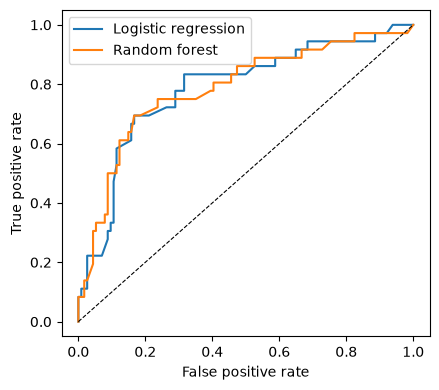

{'n_rows': 748, 'n_train': 598, 'n_test': 150, 'positive_rate': 0.238}


,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Majority baseline,0.763 +/- 0.004,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,0.760,0.000,0.000,0.000,0.500
1,Logistic regression,0.647 +/- 0.064,0.383 +/- 0.055,0.747 +/- 0.065,0.505 +/- 0.055,0.739 +/- 0.036,0.713,0.448,0.833,0.583,0.785
2,Random forest,0.671 +/- 0.038,0.380 +/- 0.042,0.606 +/- 0.083,0.466 +/- 0.050,0.715 +/- 0.038,0.720,0.450,0.750,0.562,0.786


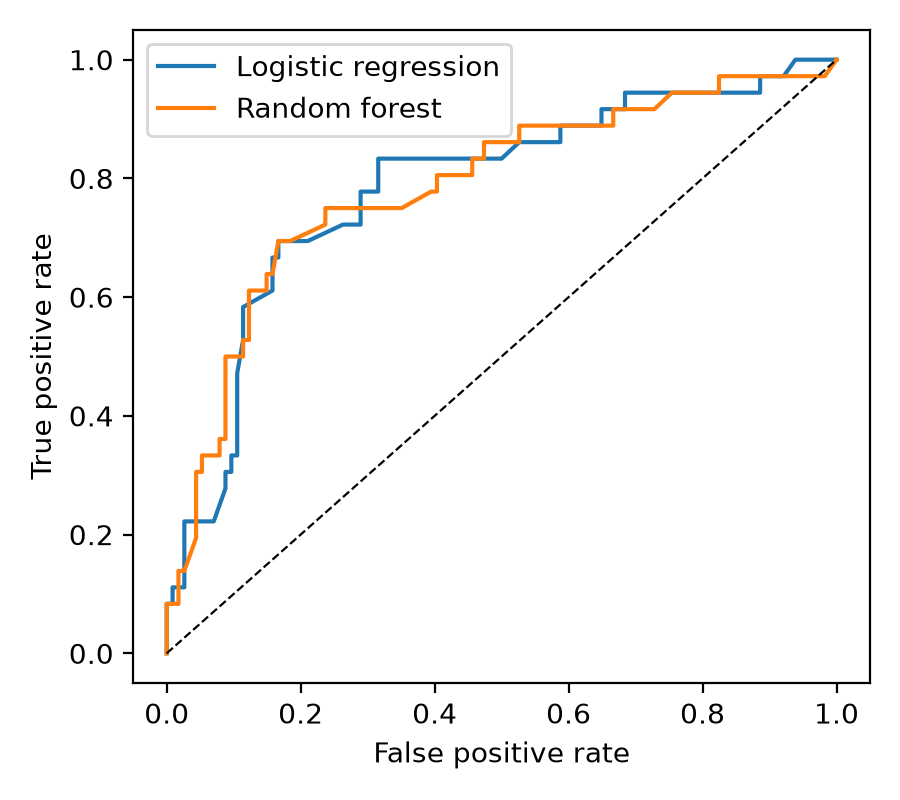

In [8]:
table_A, info_A = run_donor_model(DATA_PATH, OUT)
print(info_A)
display(table_A)
display(Image(str(OUT / "donor_model_roc.png")))

## Run Part B: matching simulation
Simulation with synthetic donors, so report it as a simulation, not a clinical validation.

In [9]:
table_B, info_B = run_matching_simulation(OUT)
print(info_B)
display(table_B)

{'n_donors': 500, 'n_requests': 1000, 'k': 5, 'share_of_donors_eligible': 0.536}


,strategy,usable_share@5,mean_dist_of_usable_km,requests_with_usable_donor_within_5km
0,proposed,0.973,6.93,0.781
1,nearest_only,0.183,1.31,0.474
2,random_compatible,0.973,16.59,0.297


## Run Part C: demand forecasting

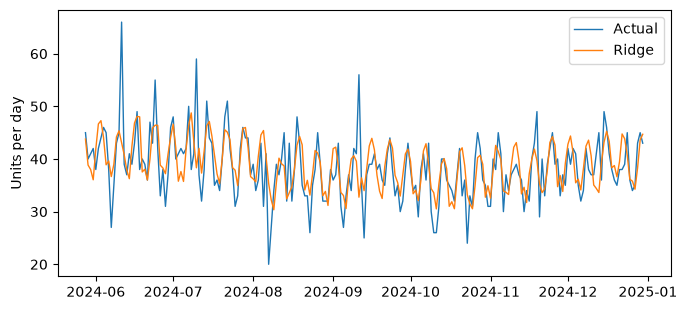

{'synthetic_data': True, 'n_days': 1095, 'n_train': 864, 'n_test': 217}


,model,MAE,RMSE,sMAPE_%
0,Naive (yesterday),5.41,7.04,14.08
1,7-day moving average,4.58,6.00,12.00
2,Seasonal naive (same weekday last week),5.00,6.78,13.15
3,Ridge on lag features,3.55,4.94,9.30


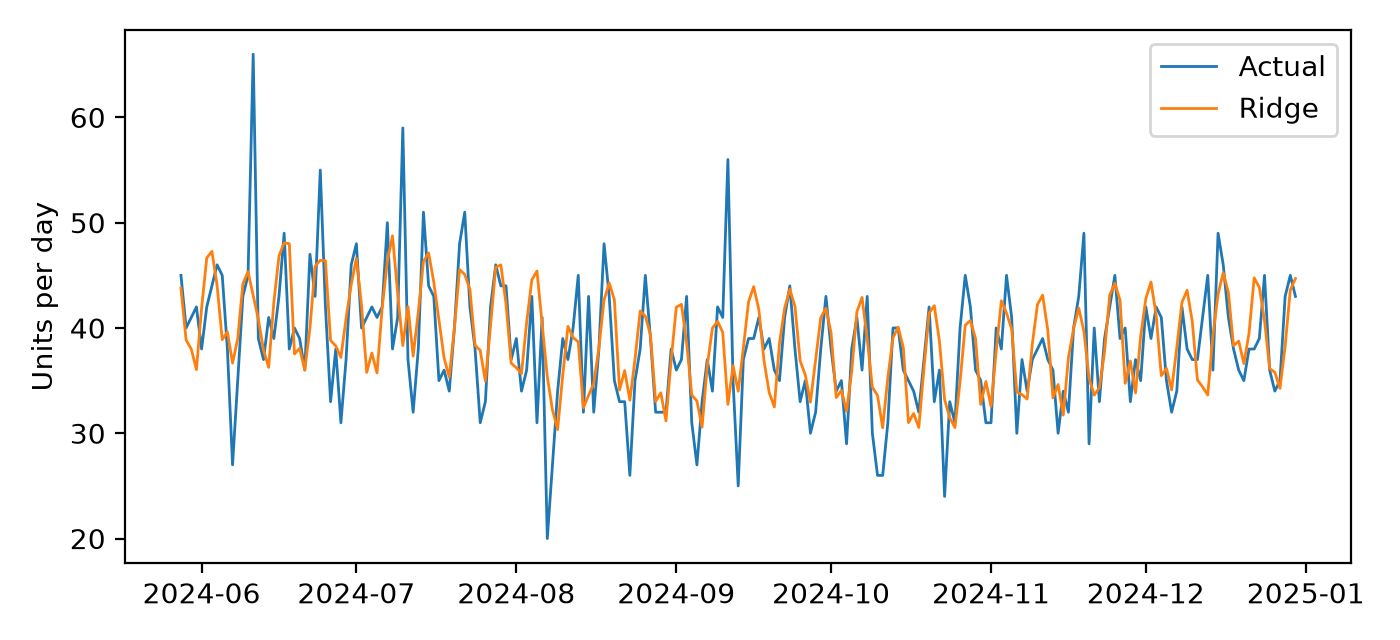

In [10]:
table_C, info_C = run_forecasting(OUT, DEMAND_CSV)
print(info_C)
display(table_C)
if info_C["synthetic_data"]:
    print("WARNING: part C used SYNTHETIC data. Do not report it as real-world results.")
display(Image(str(OUT / "forecast_plot.png")))

## Part A2 / B2 functions: stronger ML evidence
Adds confidence intervals, light tuning and a campaign-lift measure for the donor model (A2), and a 30-seed matching simulation with fairer baselines and sensitivity checks (B2).

In [11]:
# --------------------------------------------------------------------------
# A2. Stronger evaluation of the donor-return model
# --------------------------------------------------------------------------
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV

def _boot(y, p_list, fn, n=2000, seed=SEED):
    """Bootstrap 95% CI of fn(y, *p_list) over the test set."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y); vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if len(np.unique(y[b])) < 2:
            continue
        vals.append(fn(y[b], *[np.asarray(p)[b] for p in p_list]))
    return np.percentile(vals, [2.5, 97.5])


def run_donor_model_strong(path, outdir, n_boot=2000):
    df = load_transfusion(path)
    X, y = df.drop(columns="target"), df["target"]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED)   # same split as Part A
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
    lr = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=inner, scoring="roc_auc")
    rf = GridSearchCV(
        RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED),
        {"max_depth": [3, 5, 8], "min_samples_leaf": [3, 5, 10]}, cv=inner, scoring="roc_auc")
    tuned = {"Logistic regression (tuned)": lr, "Random forest (tuned)": rf}
    rows, probs = [], {}
    for name, gs in tuned.items():
        gs.fit(X_tr, y_tr)
        prob = gs.predict_proba(X_te)[:, 1]; pred = gs.predict(X_te)
        probs[name] = prob
        m = metrics(y_te, pred, prob)
        lo, hi = _boot(y_te, [prob], roc_auc_score, n_boot)
        # repeated CV (5 x 10) of the selected configuration, on the training set
        rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
        cvr = cross_validate(gs.best_estimator_, X_tr, y_tr, cv=rcv, scoring=["roc_auc", "recall", "precision", "f1"])
        rows.append({"model": name, "best_params": str(gs.best_params_),
                     "test_roc_auc": round(m["roc_auc"], 3),
                     "test_roc_auc_95CI": f"[{lo:.3f}, {hi:.3f}]",
                     "test_recall": round(m["recall"], 3), "test_precision": round(m["precision"], 3),
                     "test_f1": round(m["f1"], 3),
                     "repeatedCV_auc": f"{cvr['test_roc_auc'].mean():.3f} +/- {cvr['test_roc_auc'].std():.3f}",
                     "repeatedCV_f1": f"{cvr['test_f1'].mean():.3f} +/- {cvr['test_f1'].std():.3f}"})
    table = pd.DataFrame(rows)
    # paired bootstrap on the AUC difference between the two models
    a, b = list(probs.values())
    rng = np.random.default_rng(SEED); yy = np.asarray(y_te); diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(yy), len(yy))
        if len(np.unique(yy[i])) < 2: continue
        diffs.append(roc_auc_score(yy[i], a[i]) - roc_auc_score(yy[i], b[i]))
    d_lo, d_hi = np.percentile(diffs, [2.5, 97.5])
    # campaign usefulness: return rate among the top-scored 30% of test donors
    base = float(yy.mean()); lift_rows = []
    for name, p in probs.items():
        k = max(1, int(0.3 * len(p))); top = np.argsort(-p)[:k]
        lift_rows.append({"model": name, "base_return_rate": round(base, 3),
                          "return_rate_in_top30pct": round(float(yy[top].mean()), 3),
                          "lift": round(float(yy[top].mean()) / base, 2),
                          "share_of_all_returners_captured": round(float(yy[top].sum()) / yy.sum(), 3)})
    lift = pd.DataFrame(lift_rows)
    table.to_csv(outdir / "donor_model_strong.csv", index=False)
    lift.to_csv(outdir / "donor_model_lift.csv", index=False)
    info = {"auc_diff_LR_minus_RF_95CI": [round(float(d_lo), 3), round(float(d_hi), 3)], "n_test": len(y_te)}
    return table, lift, info


# --------------------------------------------------------------------------
# B2. Robustness of the matching simulation (30 seeds, more baselines, sensitivity)
# --------------------------------------------------------------------------
GROUP_P = {
    "assumed (O+/B+/A+ common)": [0.02, 0.28, 0.02, 0.22, 0.02, 0.32, 0.01, 0.06],
    "uniform over 8 groups":     [1 / 8] * 8,
    "O+ dominant":               [0.03, 0.45, 0.02, 0.18, 0.02, 0.22, 0.01, 0.07],
}
COMPAT_MATRIX = np.array([[need in COMPATIBLE[g] for need in GROUPS] for g in GROUPS])  # donor x need


def simulate_matching(n_donors=500, n_requests=1000, k=5, radius_km=5, p_respond=0.3,
                      probs=None, seed=SEED):
    rng = np.random.default_rng(seed)
    p = np.array(probs if probs is not None else GROUP_P["assumed (O+/B+/A+ common)"], float)
    p = p / p.sum()
    g = rng.choice(len(GROUPS), n_donors, p=p)
    age = rng.integers(16, 70, n_donors); wt = rng.normal(68, 12, n_donors)
    hb = rng.normal(13.8, 1.3, n_donors); days = rng.integers(10, 400, n_donors)
    lat = 24.86 + rng.uniform(-0.15, 0.15, n_donors); lon = 67.01 + rng.uniform(-0.15, 0.15, n_donors)
    elig = ((age >= RULES["min_age"]) & (age <= RULES["max_age"]) & (wt >= RULES["min_weight_kg"])
            & (hb >= RULES["min_hb_g_dl"]) & (days >= RULES["min_days_since_last"]))
    strategies = ["proposed", "nearest_only", "nearest_compatible", "nearest_eligible", "random_compatible_eligible"]
    out = {s: {"usable": [], "dist": [], "within": [], "respond": []} for s in strategies}
    short = 0
    for _ in range(n_requests):
        need = rng.integers(len(GROUPS))
        hl, ho = 24.86 + rng.uniform(-0.15, 0.15), 67.01 + rng.uniform(-0.15, 0.15)
        dist = haversine_km(hl, ho, lat, lon)
        comp = COMPAT_MATRIX[g, need]; usable = comp & elig
        if usable.sum() < k: short += 1
        def nearest(mask):
            idx = np.where(mask)[0]
            return idx[np.argsort(dist[idx])[:k]]
        picks = {"proposed": nearest(usable), "nearest_only": nearest(np.ones(n_donors, bool)),
                 "nearest_compatible": nearest(comp), "nearest_eligible": nearest(elig)}
        ue = np.where(usable)[0]
        picks["random_compatible_eligible"] = rng.choice(ue, min(k, len(ue)), replace=False)
        for s, idx in picks.items():
            u = usable[idx]; near = u & (dist[idx] <= radius_km)
            out[s]["usable"].append(u.sum() / k)
            out[s]["dist"].append(dist[idx][u].mean() if u.any() else np.nan)
            out[s]["within"].append(bool(near.any()))
            out[s]["respond"].append(1 - (1 - p_respond) ** near.sum())
    res = {s: {"usable_share": np.mean(v["usable"]), "mean_dist_usable_km": np.nanmean(v["dist"]),
               "usable_within_radius": np.mean(v["within"]), "p_response_within_radius": np.mean(v["respond"])}
           for s, v in out.items()}
    return res, short / n_requests, float(elig.mean())


def run_matching_robustness(outdir, seeds=30):
    # main scenario: 30 independent donor pools and request streams
    runs = [simulate_matching(seed=SEED + s)[0] for s in range(seeds)]
    rows = []
    for s in runs[0]:
        row = {"strategy": s}
        for m in runs[0][s]:
            v = np.array([r[s][m] for r in runs])
            row[m] = f"{v.mean():.3f} +/- {v.std():.3f}" if m != "mean_dist_usable_km" else f"{v.mean():.2f} +/- {v.std():.2f}"
        rows.append(row)
    main = pd.DataFrame(rows)
    # sensitivity: blood group mix x pool size (proposed vs nearest-only vs nearest-compatible)
    srows = []
    for gname, gp in GROUP_P.items():
        for n in (200, 500, 1000):
            rs = [simulate_matching(n_donors=n, probs=gp, seed=SEED + s)[0] for s in range(10)]
            for s in ("proposed", "nearest_compatible", "nearest_only"):
                srows.append({"group_mix": gname, "n_donors": n, "strategy": s,
                              "usable_share": round(np.mean([r[s]["usable_share"] for r in rs]), 3),
                              "p_response_within_5km": round(np.mean([r[s]["p_response_within_radius"] for r in rs]), 3)})
    sens = pd.DataFrame(srows)
    _, short, elig_share = simulate_matching(seed=SEED)
    main.to_csv(outdir / "matching_robustness_main.csv", index=False)
    sens.to_csv(outdir / "matching_robustness_sensitivity.csv", index=False)
    return main, sens, {"seeds": seeds, "share_requests_with_fewer_than_k_usable_donors": round(short, 3),
                        "share_of_donors_eligible": round(elig_share, 3)}

## Run Part A2: stronger donor-model evaluation
Takes about a minute. Report the `test_roc_auc_95CI` column and the lift table in the paper.

In [12]:
table_A2, lift_A2, info_A2 = run_donor_model_strong(DATA_PATH, OUT)
print(info_A2)
display(table_A2)
display(lift_A2)

{'auc_diff_LR_minus_RF_95CI': [-0.047, 0.035], 'n_test': 150}


,model,best_params,test_roc_auc,test_roc_auc_95CI,test_recall,test_precision,test_f1,repeatedCV_auc,repeatedCV_f1
0,Logistic regression (tuned),{'logisticregression__C': 10},0.785,"[0.688, 0.872]",0.833,0.455,0.588,0.741 +/- 0.044,0.497 +/- 0.046
1,Random forest (tuned),"{'max_depth': 5, 'min_samples_leaf': 10}",0.790,"[0.695, 0.876]",0.750,0.458,0.568,0.726 +/- 0.052,0.476 +/- 0.054


,model,base_return_rate,return_rate_in_top30pct,lift,share_of_all_returners_captured
0,Logistic regression (tuned),0.24,0.556,2.31,0.694
1,Random forest (tuned),0.24,0.556,2.31,0.694


## Run Part B2: matching robustness (synthetic donors)

In [13]:
main_B2, sens_B2, info_B2 = run_matching_robustness(OUT)
print(info_B2)
display(main_B2)
display(sens_B2)

{'seeds': 30, 'share_requests_with_fewer_than_k_usable_donors': 0.13, 'share_of_donors_eligible': 0.534}


,strategy,usable_share,mean_dist_usable_km,usable_within_radius,p_response_within_radius
0,proposed,0.983 +/- 0.022,6.70 +/- 0.76,0.766 +/- 0.041,0.514 +/- 0.025
1,nearest_only,0.191 +/- 0.013,1.32 +/- 0.02,0.479 +/- 0.024,0.229 +/- 0.014
2,nearest_compatible,0.542 +/- 0.060,4.71 +/- 0.39,0.757 +/- 0.042,0.404 +/- 0.028
3,nearest_eligible,0.342 +/- 0.016,1.79 +/- 0.05,0.580 +/- 0.027,0.346 +/- 0.015
4,random_compatible_eligible,0.983 +/- 0.022,16.69 +/- 0.47,0.289 +/- 0.018,0.095 +/- 0.006


,group_mix,n_donors,strategy,usable_share,p_response_within_5km
0,assumed (O+/B+/A+ common),200,proposed,0.886,0.394
1,assumed (O+/B+/A+ common),200,nearest_compatible,0.547,0.332
2,assumed (O+/B+/A+ common),200,nearest_only,0.194,0.230
3,assumed (O+/B+/A+ common),500,proposed,0.975,0.504
4,assumed (O+/B+/A+ common),500,nearest_compatible,0.547,0.396
5,assumed (O+/B+/A+ common),500,nearest_only,0.189,0.226
6,assumed (O+/B+/A+ common),1000,proposed,1.000,0.601
7,assumed (O+/B+/A+ common),1000,nearest_compatible,0.560,0.479
8,assumed (O+/B+/A+ common),1000,nearest_only,0.190,0.228
9,uniform over 8 groups,200,proposed,1.000,0.549


## Save everything

In [14]:
summary = {"donor_model": {"info": info_A, "table": table_A.to_dict("records")},
           "matching": {"info": info_B, "table": table_B.to_dict("records")},
           "forecasting": {"info": info_C, "table": table_C.to_dict("records")},
           "donor_model_strong": {"info": info_A2, "table": table_A2.to_dict("records"), "lift": lift_A2.to_dict("records")},
           "matching_robustness": {"info": info_B2, "main": main_B2.to_dict("records"), "sensitivity": sens_B2.to_dict("records")}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved all results to:", OUT.resolve())

Saved all results to: C:\Users\Musheer Baig\results
